# Multilevel Analysis for Retrospective Confidence, Perceived Individual Performance, and Team Gameplay Outcome based on Skin Conductance Response

by Elvis Ortega-Ochoa

In [1]:
import sys
import subprocess

subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade", "pip", "ipywidgets", "jupyterlab_widgets"])
subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "pymer4",
    "rpy2",
    "polars",
    "great-tables",
    "joblib",
    "scikit-learn",
    "pyarrow",
    "bambi",
    "arviz",
    "matplotlib",
    "pandas",
    "numpy",
    "statsmodels",
    "openpyxl",
])

0

Packages

In [55]:
import pandas as pd
import numpy as np
import bambi as bmb
import arviz as az
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import matplotlib.patches as patches
import statsmodels.api as sm
import pymer4.models as pm
import polars as pl
import ipywidgets as widgets
from pymer4.models import lmer as Lmer

Loading data

In [3]:
# Reading files and printing columns
scr = pd.read_excel("../../confidence_SCR/stable_scr_events_UPD.xlsx", keep_default_na=False)     
cf = pd.read_excel("../../confidence_SCR/CONT_dependent_variables_confidence_E.xlsx", keep_default_na=False)

# Make a clean copy
scr = scr.copy()
cf = cf.copy()

# Extract participantID and sensorID from scrID
scr["participantID"] = scr["scrID"].str.extract(r"SCR_([^.]+)\.")
scr["sensorID"] = scr["scrID"].str.extract(r"\.([A-Z]{2})-EDA$")

# Merge the dataframes on groupID, participantID, and sensorID
dataset = scr.merge(
    cf,
    on=["groupID", "participantID", "sensorID"],
    how="inner"
)

# Rename columns for clarity
dataset = dataset.rename(columns={
    "realGamePeaks/m": "realGamePeaks_per_m",
    "realTutoPeaks/m": "realTutoPeaks_per_m",
    "realQuestionsPeaks/m": "realQuestionsPeaks_per_m",
    "realPitchPeaks/m": "realPitchPeaks_per_m",
    "CF1": "cf",
    "PP1": "pp"
})

Build questionPath as numeric

In [4]:
# Build numeric questionPath at group level
dataset["qBonusPeaks"] = pd.to_numeric(dataset["qBonusPeaks"], errors="coerce")
dataset["qPenaltyPeaks"] = pd.to_numeric(dataset["qPenaltyPeaks"], errors="coerce")

dataset["has_bonus"] = dataset["qBonusPeaks"].notna()
dataset["has_penalty"] = dataset["qPenaltyPeaks"].notna()

group_path = (
    dataset.groupby("groupID")[["has_bonus", "has_penalty"]]
    .any()
    .reset_index()
)

group_path["questionPath"] = np.select(
    [
        group_path["has_bonus"] & ~group_path["has_penalty"],
        group_path["has_penalty"] & ~group_path["has_bonus"],
    ],
    [1, 0],
    default=np.nan,
)

# Drop any existing questionPath variants to avoid suffixes, then merge
dataset = dataset.drop(columns=[c for c in dataset.columns if c.startswith("questionPath")], errors="ignore")
dataset = dataset.merge(group_path[["groupID", "questionPath"]], on="groupID", how="left")

Reverse team gameplay score

In [5]:
# Build numeric uncertScore
dataset["uncertScore"] = pd.to_numeric(dataset["uncertScore"], errors="coerce")

# Reverse-coding, using the instrument's theoretical bounds, not the sample's
SCALE_MIN, SCALE_MAX = 1, 70  # instrument range, per ¶102
dataset["uncertScore"] = (SCALE_MIN + SCALE_MAX) - dataset["uncertScore"]

# Reverse-score uncertScore using the observed scale range
#dataset["uncertScore"] = dataset["uncertScore"].max() + dataset["uncertScore"].min() - dataset["uncertScore"]

In [6]:
# Finalize data types
dataset["groupID"] = dataset["groupID"].astype("category")
dataset["cf"] = pd.to_numeric(dataset["cf"], errors="coerce")
dataset["questionPath"] = pd.Categorical(dataset["questionPath"], categories=[0,1])

In [7]:
# Keep just variables needed
dat_model = dataset[["groupID", "participantID", "cf", "pp", "uncertScore", "realGamePeaks_per_m", "realTutoPeaks_per_m", "realQuestionsPeaks_per_m", "realPitchPeaks_per_m", "questionPath", "pitchRole"]].copy()

## Mixed Linear Models

### Within/Between Descomposition

In [58]:

def add_within_between(df, raw_col, prefix):
    group_mean = df.groupby("groupID")[raw_col].transform("mean")
    within = df[raw_col] - group_mean
    between = group_mean - group_mean.mean()

    df[f"{prefix}_group_mean"] = group_mean
    df[f"{prefix}_within"] = within
    df[f"{prefix}_between"] = between

    return df

dat_model = add_within_between(dat_model, "realGamePeaks_per_m", "scr")
dat_model = add_within_between(dat_model, "realTutoPeaks_per_m", "tuto")
dat_model = add_within_between(dat_model, "realQuestionsPeaks_per_m", "questions")
dat_model = add_within_between(dat_model, "realPitchPeaks_per_m", "pitch")
dat_model = add_within_between(dat_model, "pp", "pp")
dat_model = add_within_between(dat_model, "cf", "cf")

### Standarize predictor variables

In [64]:
dat_model["realGamePeaks_per_m_z"] = (
    dat_model["realGamePeaks_per_m"] - dat_model["realGamePeaks_per_m"].mean()
) / dat_model["realGamePeaks_per_m"].std()

dat_model["scr_within_z"] = (
    dat_model["scr_within"] - dat_model["scr_within"].mean()
) / dat_model["scr_within"].std()

dat_model["scr_between_z"] = (
    dat_model["scr_between"] - dat_model["scr_between"].mean()
) / dat_model["scr_between"].std()

dat_model["tuto_within_z"] = (
    dat_model["tuto_within"] - dat_model["tuto_within"].mean()
) / dat_model["tuto_within"].std()

dat_model["tuto_between_z"] = (
    dat_model["tuto_between"] - dat_model["tuto_between"].mean()
) / dat_model["tuto_between"].std()

dat_model["questions_within_z"] = (
    dat_model["questions_within"] - dat_model["questions_within"].mean()
) / dat_model["questions_within"].std()

dat_model["questions_between_z"] = (
    dat_model["questions_between"] - dat_model["questions_between"].mean()
) / dat_model["questions_between"].std()

dat_model["pitch_within_z"] = (
    dat_model["pitch_within"] - dat_model["pitch_within"].mean()
) / dat_model["pitch_within"].std()

dat_model["pitch_between_z"] = (
    dat_model["pitch_between"] - dat_model["pitch_between"].mean()
) / dat_model["pitch_between"].std()

dat_model["pp_z"] = (
    dat_model["pp"] - dat_model["pp"].mean()
) / dat_model["pp"].std()

dat_model["pp_within_z"] = (
    dat_model["pp_within"] - dat_model["pp_within"].mean()
) / dat_model["pp_within"].std()

dat_model["pp_between_z"] = (
    dat_model["pp_between"] - dat_model["pp_between"].mean()
) / dat_model["pp_between"].std()

dat_model["uncertScore_z"] = (
    dat_model["uncertScore"] - dat_model["uncertScore"].mean()
) / dat_model["uncertScore"].std()

dat_model["cf_z"] = (
    dat_model["cf"] - dat_model["cf"].mean()
) / dat_model["cf"].std()

dat_model["cf_within_z"] = (
    dat_model["cf_within"] - dat_model["cf_within"].mean()
) / dat_model["cf_within"].std()

dat_model["cf_between_z"] = (
    dat_model["cf_between"] - dat_model["cf_between"].mean()
) / dat_model["cf_between"].std()

dat_model.columns.tolist()

# Team-level dataset (one row per team, n = 29) for team gameplay score models
team_model = dat_model.drop_duplicates(subset="groupID").copy()

Pitch data cleaning

In [67]:
dat_model['pitchRole'] = pd.to_numeric(dat_model['pitchRole'], errors='coerce')
dat_model_pitch_role = dat_model.dropna(subset=['groupID',
 'participantID',
 'cf',
 'pp',
 'uncertScore',
 'realGamePeaks_per_m',
 'realTutoPeaks_per_m',
 'realQuestionsPeaks_per_m',
 'realPitchPeaks_per_m',
 'questionPath',
 'pitchRole',
 'scr_group_mean',
 'scr_within',
 'scr_between',
 'tuto_group_mean',
 'tuto_within',
 'tuto_between',
 'questions_group_mean',
 'questions_within',
 'questions_between',
 'pitch_group_mean',
 'pitch_within',
 'pitch_between',
 'pp_group_mean',
 'pp_within',
 'pp_between',
 'realGamePeaks_per_m_z',
 'scr_within_z',
 'scr_between_z',
 'tuto_within_z',
 'tuto_between_z',
 'questions_within_z',
 'questions_between_z',
 'pitch_within_z',
 'pitch_between_z',
 'pp_z',
 'pp_within_z',
 'pp_between_z',
 'uncertScore_z',
 'cf_z',
 'cf_within_z',
 'cf_between_z']).copy()

dat_model_pitch_role = dat_model_pitch_role[dat_model_pitch_role['pitchRole'].isin([0, 1])].copy()

# Finalize data type
dat_model_pitch_role["pitchRole"] = pd.Categorical(dat_model_pitch_role["pitchRole"], categories=[0, 1])

## Exploratory Data Analysis

Missing values:
cf                          0
pp                          0
uncertScore                 0
realGamePeaks_per_m         0
realTutoPeaks_per_m         0
realQuestionsPeaks_per_m    0
realPitchPeaks_per_m        0
dtype: int64 

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
cf,87.0,3.425287,1.559906,1.000000,2.000000,3.000000,5.000000,7.000000
pp,87.0,6.494253,1.764466,2.000000,5.000000,7.000000,8.000000,10.000000
uncertScore,87.0,33.482759,7.603338,11.000000,30.000000,34.000000,37.000000,46.000000
realGamePeaks_per_m,87.0,2.114204,2.406057,-4.070671,0.358493,2.079011,3.722039,8.403172
realTutoPeaks_per_m,87.0,2.989865,2.548684,-3.124891,1.270447,2.378785,5.282077,8.361345
realQuestionsPeaks_per_m,87.0,1.800861,2.490374,-4.446577,0.189259,1.723939,3.370871,9.234457
realPitchPeaks_per_m,87.0,2.272550,3.905028,-11.221374,0.346963,2.019637,4.973874,9.502378


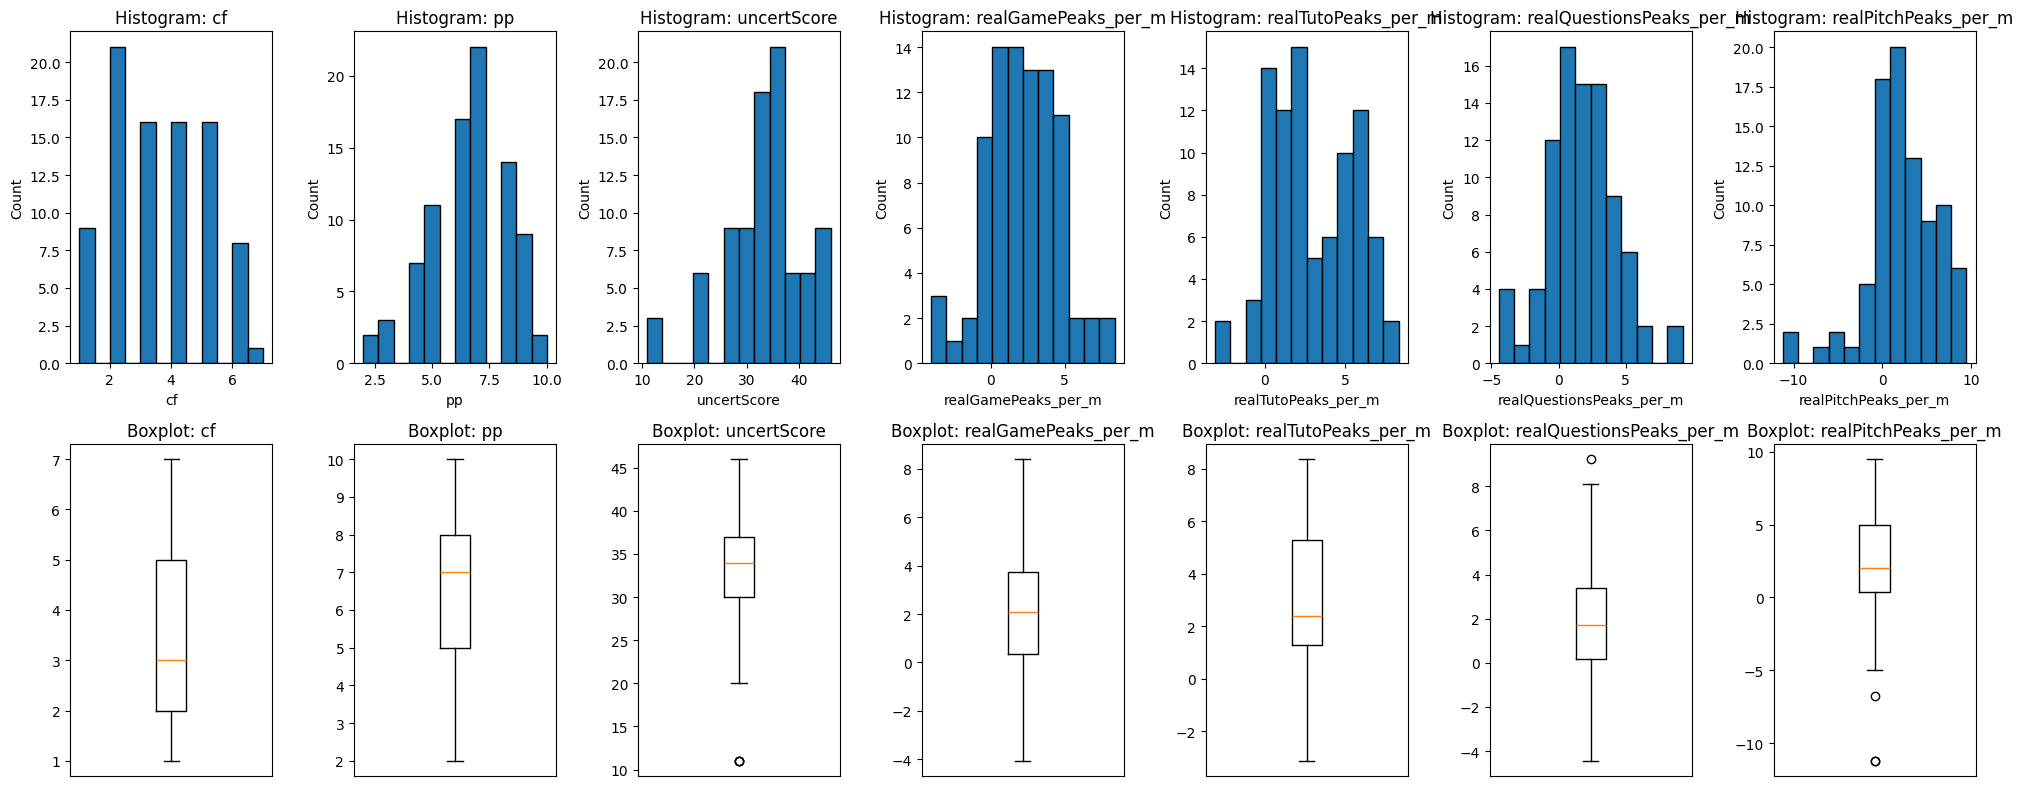

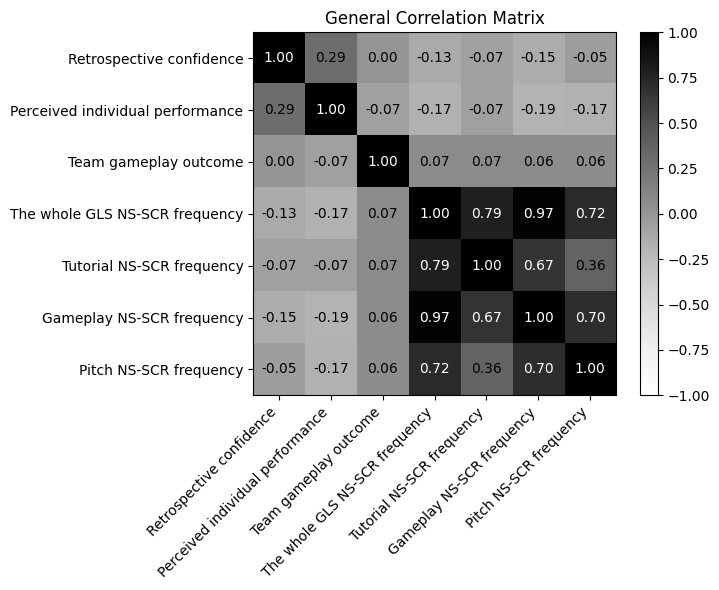

In [22]:
cols = ["cf", "pp", "uncertScore", "realGamePeaks_per_m", "realTutoPeaks_per_m", "realQuestionsPeaks_per_m", "realPitchPeaks_per_m"]

# Labels to display
labels = {
    "cf": "Retrospective confidence",
    "pp": "Perceived individual performance",
    "pp_within": "Within-team PIP",
    "pp_between": "Between-team PIP",
    "uncertScore": "Team gameplay outcome",
    "realGamePeaks_per_m": "The whole GLS NS-SCR frequency",
    "scr_within": "Within-team the whole GLS NS-SCR frequency",
    "scr_between": "Between-team the whole GLS NS-SCR frequency",
    "realTutoPeaks_per_m": "Tutorial NS-SCR frequency",
    "tuto_within": "Within-team tutorial NS-SCR frequency",
    "tuto_between": "Between-team tutorial NS-SCR frequency",
    "realQuestionsPeaks_per_m": "Gameplay NS-SCR frequency",
    "questions_within": "Within-team gameplay NS-SCR frequency",
    "questions_between": "Between-team gameplay NS-SCR frequency",
    "realPitchPeaks_per_m": "Pitch NS-SCR frequency",
    "pitch_within": "Within-team pitch NS-SCR frequency",
    "pitch_between": "Between-team pitch NS-SCR frequency"
}

# Basic summary
print("Missing values:")
print(dat_model[cols].isna().sum(), "\n")

print("Descriptive statistics:")
display(dat_model[cols].describe().T)

# Distribution plots and boxplots
fig, axes = plt.subplots(2, len(cols), figsize=(20, 8))

for i, col in enumerate(cols):
    axes[0, i].hist(dat_model[col], bins=12, edgecolor="black")
    axes[0, i].set_title(f"Histogram: {col}")
    axes[0, i].set_xlabel(col)
    axes[0, i].set_ylabel("Count")

    axes[1, i].boxplot(dat_model[col], vert=True)
    axes[1, i].set_title(f"Boxplot: {col}")
    axes[1, i].set_xticks([])

plt.tight_layout()
plt.show()

# Correlation matrix
corr = dat_model[cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="Greys", vmin=-1, vmax=1)

display_labels = [labels[col] for col in cols]

ax.set_xticks(range(len(display_labels)))
ax.set_yticks(range(len(display_labels)))
ax.set_xticklabels(display_labels, rotation=45, ha="right")
ax.set_yticklabels(display_labels)
ax.set_title("General Correlation Matrix")

# Add correlation scores in each cell
for i in range(len(cols)):
    for j in range(len(cols)):
        value = corr.iloc[i, j]
        text_color = "white" if abs(value) > 0.5 else "black"
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", color=text_color)

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [68]:
eda_df = dat_model.copy()

eda_df[["pitch_within", "pitch_between"]] = np.nan
eda_df.loc[dat_model_pitch_role.index, ["pitch_within", "pitch_between"]] = dat_model_pitch_role[["pitch_within", "pitch_between"]].to_numpy()

cols_within_between = ["cf", "pp", "uncertScore", "scr_within", "scr_between", "tuto_within", "tuto_between","questions_within", "questions_between", "pitch_within", "pitch_between"]
cols_within = ["cf", "pp", "uncertScore", "scr_within", "tuto_within", "questions_within", "pitch_within"]
cols_between = ["cf", "pp", "uncertScore", "scr_between",  "tuto_between", "questions_between", "pitch_between"]

Within-team Exploratory Data Analysis

Missing values:
cf                  0
pp                  0
uncertScore         0
scr_within          0
tuto_within         0
questions_within    0
pitch_within        3
dtype: int64 

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
cf,87.0,3.425287e+00,1.559906,1.000000,2.000000,3.000000,5.000000,7.000000
pp,87.0,6.494253e+00,1.764466,2.000000,5.000000,7.000000,8.000000,10.000000
uncertScore,87.0,3.348276e+01,7.603338,11.000000,30.000000,34.000000,37.000000,46.000000
scr_within,87.0,4.083579e-17,1.952139,-4.228912,-1.186685,0.079387,1.136715,4.572771
tuto_within,87.0,1.020895e-17,2.049427,-3.827188,-1.513568,-0.096863,1.860652,4.003711
questions_within,87.0,-1.786566e-17,1.992601,-4.223753,-1.400472,0.153288,1.088501,5.281570
pitch_within,84.0,-1.057355e-17,3.098589,-9.181356,-1.706938,-0.176149,2.024036,10.406666


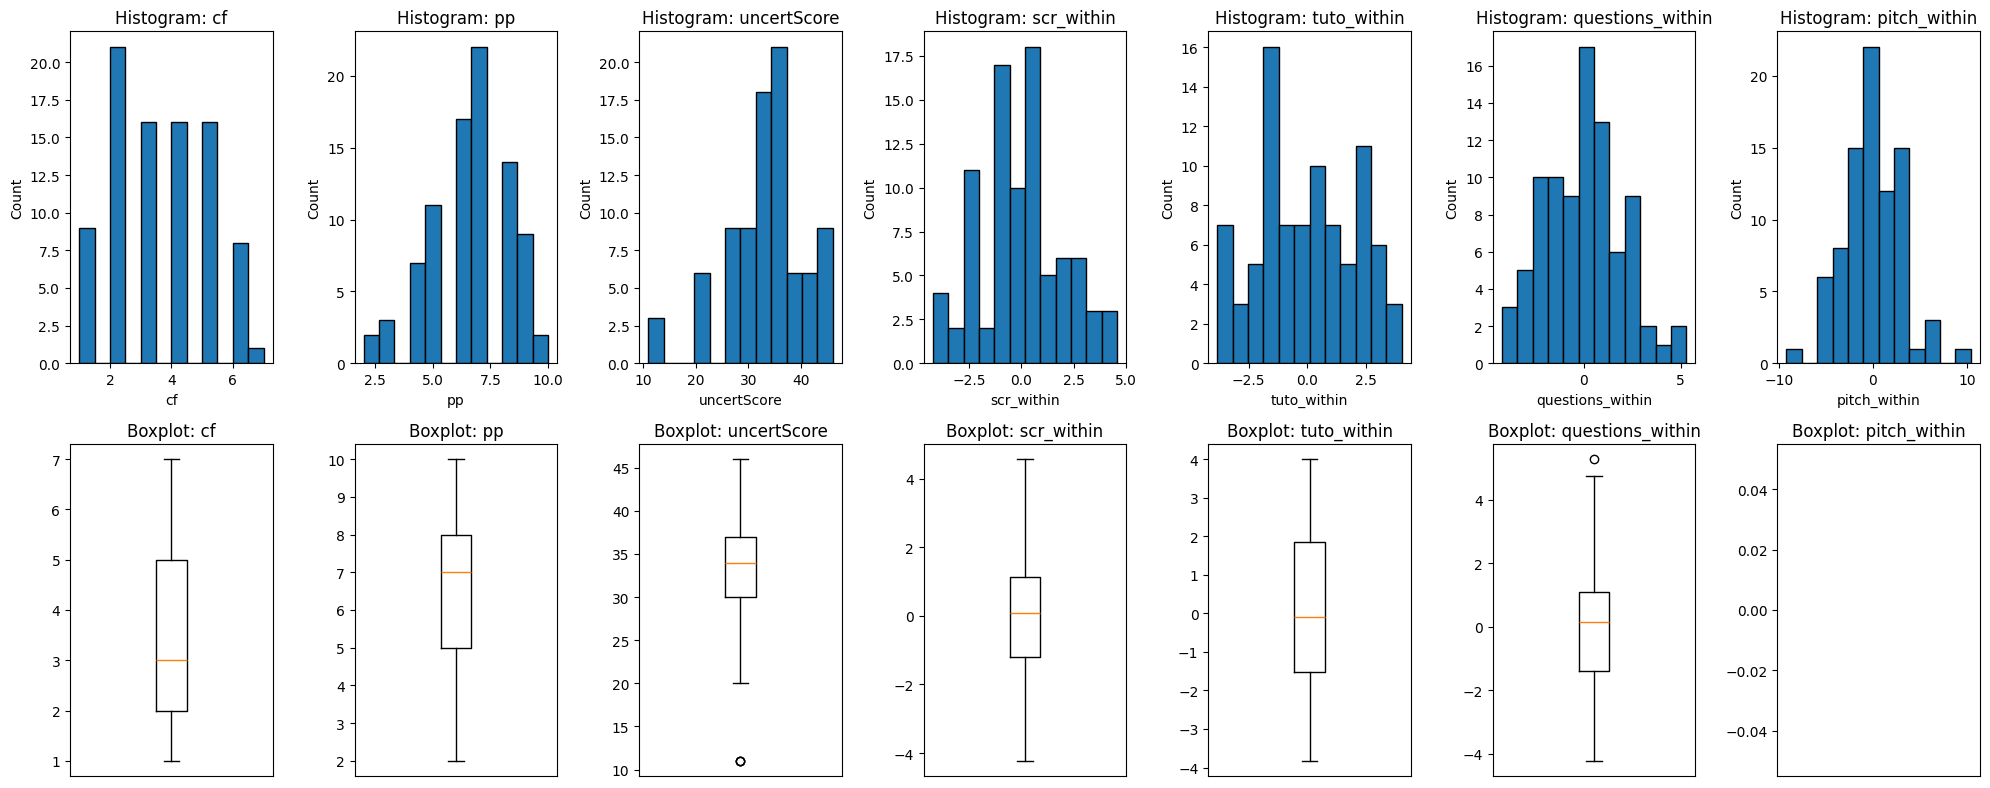

In [69]:
# Basic summary
print("Missing values:")
print(eda_df[cols_within].isna().sum(), "\n")

print("Descriptive statistics:")
display(eda_df[cols_within].describe().T)

# Distribution plots and boxplots
fig, axes = plt.subplots(2, len(cols_within), figsize=(20, 8))

for i, col in enumerate(cols_within):
    axes[0, i].hist(eda_df[col], bins=12, edgecolor="black")
    axes[0, i].set_title(f"Histogram: {col}")
    axes[0, i].set_xlabel(col)
    axes[0, i].set_ylabel("Count")

    axes[1, i].boxplot(eda_df[col], vert=True)
    axes[1, i].set_title(f"Boxplot: {col}")
    axes[1, i].set_xticks([])

plt.tight_layout()
plt.show()

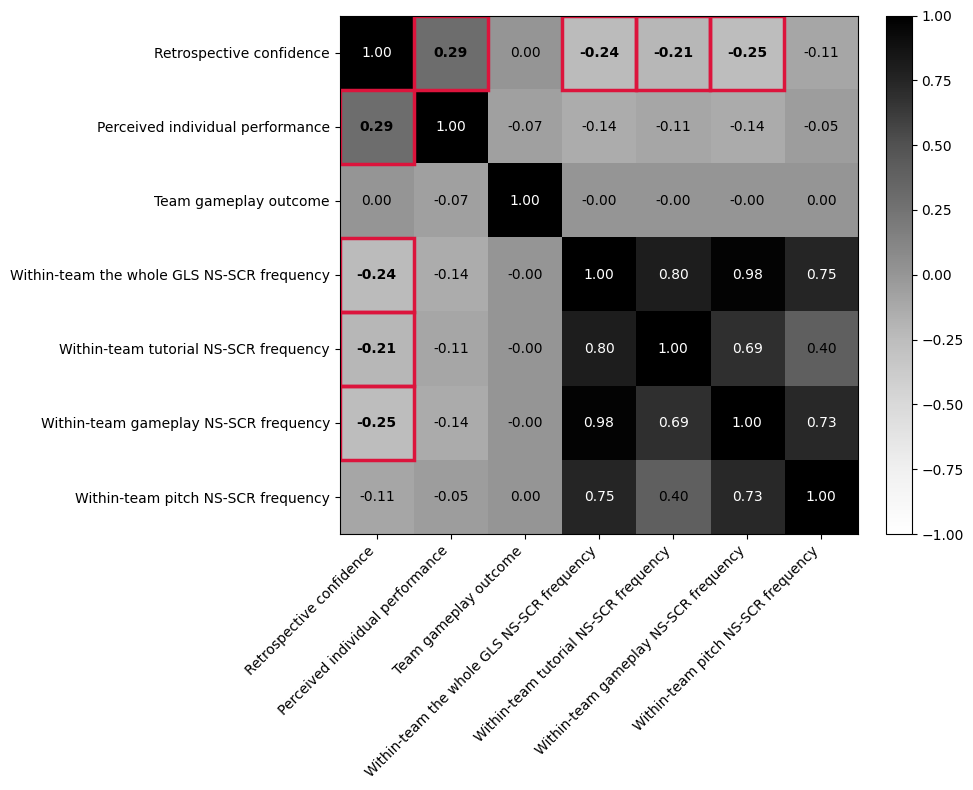

In [70]:
# Correlation matrix
corr = eda_df[cols_within].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="Greys", vmin=-1, vmax=1)

display_labels = [labels[col] for col in cols_within]

ax.set_xticks(range(len(display_labels)))
ax.set_yticks(range(len(display_labels)))
ax.set_xticklabels(display_labels, rotation=45, ha="right")
ax.set_yticklabels(display_labels)

threshold = 0.20
focus_var = "cf"

for i in range(len(cols_within)):
    for j in range(len(cols_within)):
        value = corr.iloc[i, j]
        text_color = "white" if abs(value) > 0.5 else "black"
        involves_focus = focus_var in (cols_within[i], cols_within[j])
        is_strong = abs(value) >= threshold and i != j and involves_focus
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                 color=text_color, fontweight="bold" if is_strong else "normal")
        if is_strong:
            rect = patches.Rectangle((j - 0.5, i - 0.5), 1, 1,
                                       linewidth=2.5, edgecolor="crimson", facecolor="none")
            ax.add_patch(rect)

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

Between-team Exploratory Data Analysis

Missing values:
cf                   0
pp                   0
uncertScore          0
scr_between          0
tuto_between         0
questions_between    0
pitch_between        3
dtype: int64 

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
cf,87.0,3.425287e+00,1.559906,1.000000,2.000000,3.000000,5.000000,7.000000
pp,87.0,6.494253e+00,1.764466,2.000000,5.000000,7.000000,8.000000,10.000000
uncertScore,87.0,3.348276e+01,7.603338,11.000000,30.000000,34.000000,37.000000,46.000000
scr_between,87.0,2.756416e-16,1.406507,-3.337750,-0.941966,-0.065864,0.914374,2.494181
tuto_between,87.0,-8.473426e-16,1.515138,-3.478591,-1.187725,0.369232,0.947484,2.792636
questions_between,87.0,8.167158e-17,1.493821,-3.056665,-1.009198,-0.114830,1.106064,2.363263
pitch_between,84.0,1.269501e-01,2.385979,-8.290591,-0.652798,0.139819,1.189454,4.415574


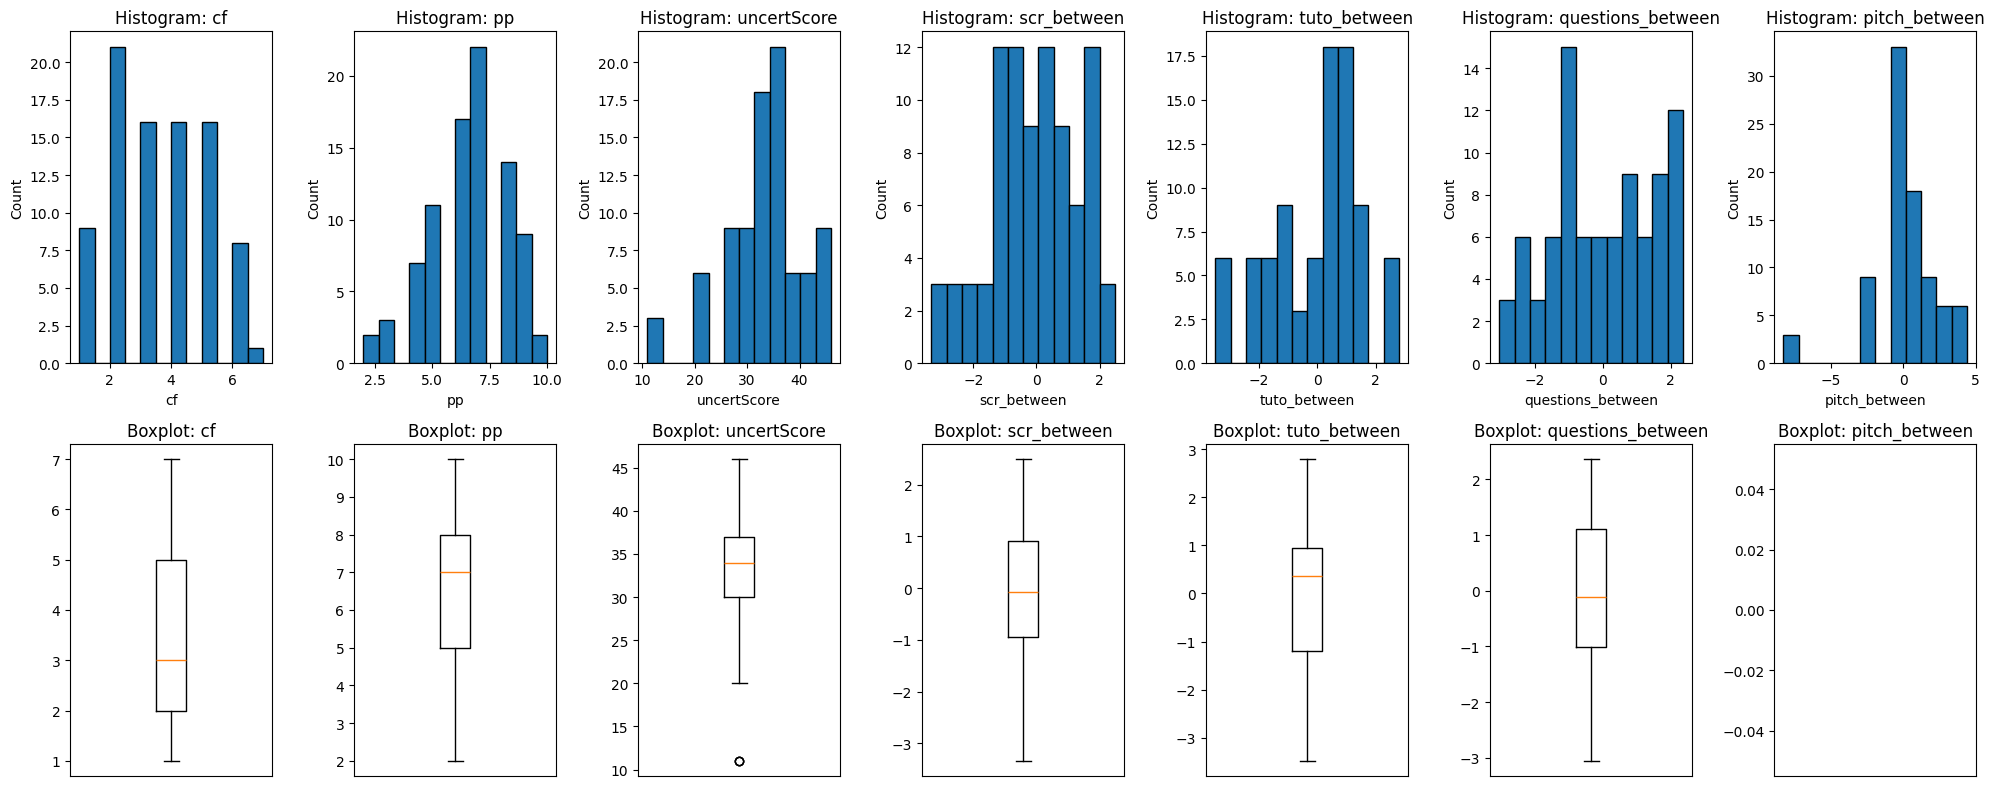

In [71]:
# Basic summary
print("Missing values:")
print(eda_df[cols_between].isna().sum(), "\n")

print("Descriptive statistics:")
display(eda_df[cols_between].describe().T)

# Distribution plots and boxplots
fig, axes = plt.subplots(2, len(cols_between), figsize=(20, 8))

for i, col in enumerate(cols_between):
    axes[0, i].hist(eda_df[col], bins=12, edgecolor="black")
    axes[0, i].set_title(f"Histogram: {col}")
    axes[0, i].set_xlabel(col)
    axes[0, i].set_ylabel("Count")

    axes[1, i].boxplot(eda_df[col], vert=True)
    axes[1, i].set_title(f"Boxplot: {col}")
    axes[1, i].set_xticks([])

plt.tight_layout()
plt.show()

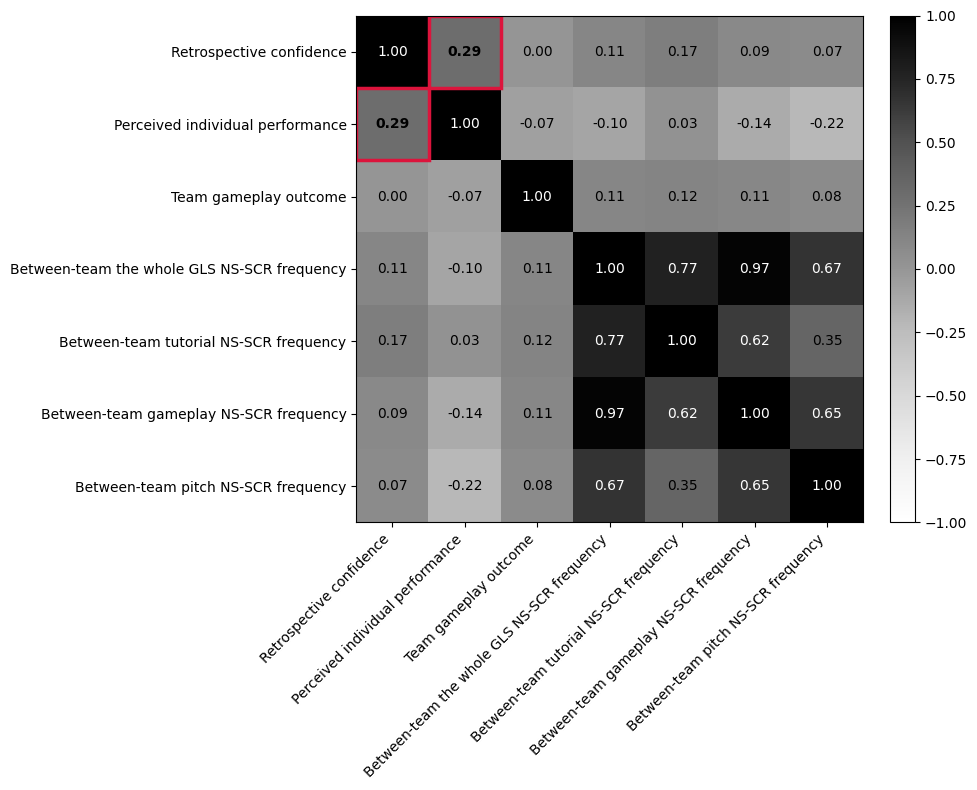

In [72]:
# Correlation matrix
corr = eda_df[cols_between].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="Greys", vmin=-1, vmax=1)

display_labels = [labels[col] for col in cols_between]

ax.set_xticks(range(len(display_labels)))
ax.set_yticks(range(len(display_labels)))
ax.set_xticklabels(display_labels, rotation=45, ha="right")
ax.set_yticklabels(display_labels)
#ax.set_title("Detailed Correlation Matrix")

threshold = 0.20
focus_var = "cf"

for i in range(len(cols_between)):
    for j in range(len(cols_between)):
        value = corr.iloc[i, j]
        text_color = "white" if abs(value) > 0.5 else "black"
        involves_focus = focus_var in (cols_between[i], cols_between[j])
        is_strong = abs(value) >= threshold and i != j and involves_focus
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                 color=text_color, fontweight="bold" if is_strong else "normal")
        if is_strong:
            rect = patches.Rectangle((j - 0.5, i - 0.5), 1, 1,
                                       linewidth=2.5, edgecolor="crimson", facecolor="none")
            ax.add_patch(rect)

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

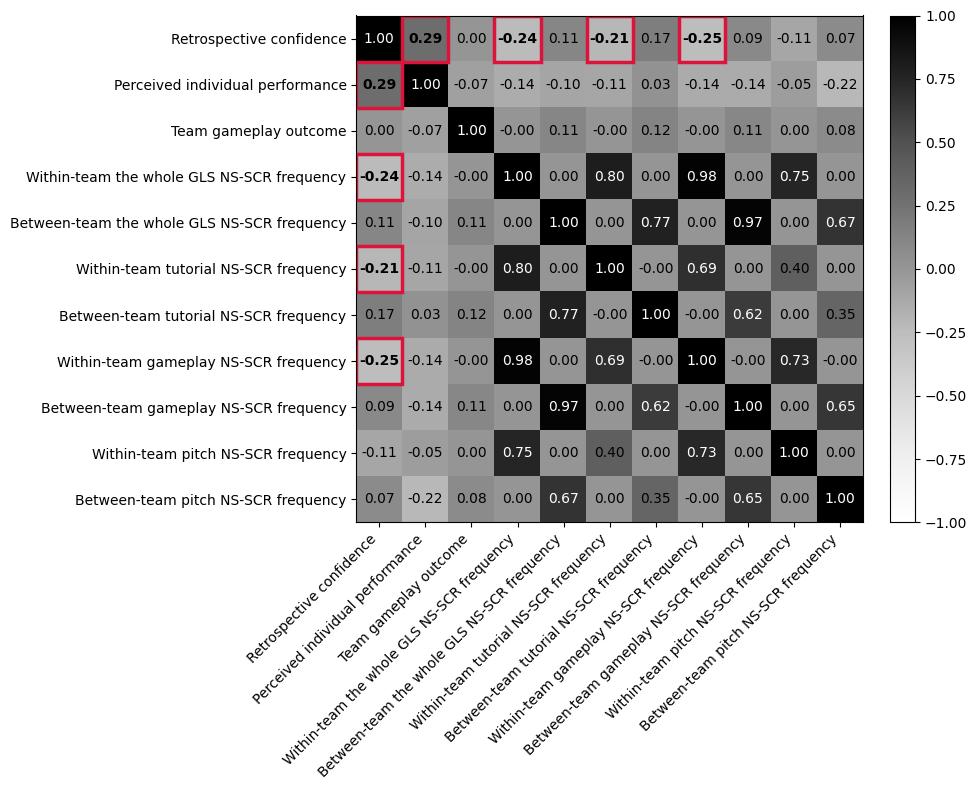

In [73]:
# Correlation matrix
corr = eda_df[cols_within_between].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="Greys", vmin=-1, vmax=1)

display_labels = [labels[col] for col in cols_within_between]

ax.set_xticks(range(len(display_labels)))
ax.set_yticks(range(len(display_labels)))
ax.set_xticklabels(display_labels, rotation=45, ha="right")
ax.set_yticklabels(display_labels)

threshold = 0.20
focus_var = "cf"

for i in range(len(cols_within_between)):
    for j in range(len(cols_within_between)):
        value = corr.iloc[i, j]
        text_color = "white" if abs(value) > 0.5 else "black"
        involves_focus = focus_var in (cols_within_between[i], cols_within_between[j])
        is_strong = abs(value) >= threshold and i != j and involves_focus
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                 color=text_color, fontweight="bold" if is_strong else "normal")
        if is_strong:
            rect = patches.Rectangle((j - 0.5, i - 0.5), 1, 1,
                                       linewidth=2.5, edgecolor="crimson", facecolor="none")
            ax.add_patch(rect)

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

### Model 1 - CF ~ realGamePeaks_per_m_z + (1|groupID)

1. Statsmodels (LME4)

In [74]:
model1_sm = sm.MixedLM.from_formula(
    "cf ~ realGamePeaks_per_m_z",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
result1_sm = model1_sm.fit(reml=True, method="lbfgs")
print("Model 1 sm: CF ~ realGamePeaks_per_m_z + (1|groupID)")
print(result1_sm.summary())

Model 1 sm: CF ~ realGamePeaks_per_m_z + (1|groupID)
             Mixed Linear Model Regression Results
Model:               MixedLM    Dependent Variable:    cf       
No. Observations:    87         Method:                REML     
No. Groups:          29         Scale:                 1.8671   
Min. group size:     3          Log-Likelihood:        -160.6816
Max. group size:     3          Converged:             Yes      
Mean group size:     3.0                                        
----------------------------------------------------------------
                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------
Intercept              3.425    0.203 16.854 0.000  3.027  3.824
realGamePeaks_per_m_z -0.298    0.167 -1.789 0.074 -0.625  0.029
groupID Var            0.575    0.295                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


2. Bambi (Robustness testing)

In [19]:
model1_bmb = bmb.Model(
    "cf ~ realGamePeaks_per_m_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model1 = model1_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 1 bmb: CF ~ realGamePeaks_per_m_z + (1|groupID)")
az.summary(idata_model1, var_names=["realGamePeaks_per_m_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, realGamePeaks_per_m_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.
There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


Model 1 bmb: CF ~ realGamePeaks_per_m_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
realGamePeaks_per_m_z,-0.293,0.174,-0.606,0.042,0.002,0.002,5495.0,4901.0,1.0
1|groupID_sigma,0.727,0.277,0.149,1.217,0.007,0.004,1695.0,1804.0,1.0
sigma,1.405,0.134,1.172,1.670,0.003,0.002,2684.0,3775.0,1.0


#### Within/Between Model 1: CF ~ scr_within_z + scr_between_z + (1|groupID)

1. Statsmodels (LME4)

In [20]:
model1_within_sm = sm.MixedLM.from_formula(
    "cf ~ scr_within_z",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
result1_within_sm = model1_within_sm.fit(reml=True, method="lbfgs")
print("Model 1 within sm: CF ~ scr_within_z + (1|groupID)")
print(result1_within_sm.summary())

Model 1 within sm: CF ~ scr_within_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: cf       
No. Observations: 87      Method:             REML     
No. Groups:       29      Scale:              1.8480   
Min. group size:  3       Log-Likelihood:     -159.2149
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
-------------------------------------------------------
             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept     3.425    0.194 17.632 0.000  3.045  3.806
scr_within_z -0.374    0.147 -2.548 0.011 -0.661 -0.086
groupID Var   0.478    0.263                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


In [21]:
model1_between_sm = sm.MixedLM.from_formula(
    "cf ~ scr_between_z",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
result1_between_sm = model1_between_sm.fit(reml=True, method="lbfgs")
print("Model 1 between sm: CF ~ scr_between_z + (1|groupID)")
print(result1_between_sm.summary())

Model 1 between sm: CF ~ scr_between_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: cf       
No. Observations: 87      Method:             REML     
No. Groups:       29      Scale:              2.0230   
Min. group size:  3       Log-Likelihood:     -161.6428
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
-------------------------------------------------------
              Coef. Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept     3.425    0.195 17.573 0.000  3.043  3.807
scr_between_z 0.177    0.196  0.901 0.368 -0.208  0.561
groupID Var   0.427    0.255                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


In [22]:
model1_within_between_sm = sm.MixedLM.from_formula(
    "cf ~ scr_within_z + scr_between_z",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
result1_within_between_sm = model1_within_between_sm.fit(reml=True, method="lbfgs")
print("Model 1 within-between sm: CF ~ scr_within_z + scr_between_z + (1|groupID)")
print(result1_within_between_sm.summary())

Model 1 within-between sm: CF ~ scr_within_z + scr_between_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:             MixedLM Dependent Variable: cf       
No. Observations:  87      Method:             REML     
No. Groups:        29      Scale:              1.8480   
Min. group size:   3       Log-Likelihood:     -159.5196
Max. group size:   3       Converged:          Yes      
Mean group size:   3.0                                  
--------------------------------------------------------
              Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------
Intercept      3.425    0.195 17.573 0.000  3.043  3.807
scr_within_z  -0.374    0.147 -2.548 0.011 -0.661 -0.086
scr_between_z  0.177    0.196  0.901 0.368 -0.208  0.561
groupID Var    0.486    0.268                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


2. Bambi (Robustness testing)

In [23]:
model1_within_bmb  = bmb.Model(
    "cf ~ scr_within_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model1_within_bmb = model1_within_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 1 within bmb: CF ~ scr_within_z + (1|groupID)")
az.summary(idata_model1_within_bmb, var_names=["scr_within_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, scr_within_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.
There were 64 divergences after tuning. Increase `target_accept` or reparameterize.


Model 1 within bmb: CF ~ scr_within_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
scr_within_z,-0.371,0.153,-0.660,-0.085,0.002,0.002,4811.0,4477.0,1.0
1|groupID_sigma,0.644,0.272,0.059,1.098,0.007,0.004,1451.0,1908.0,1.0
sigma,1.399,0.132,1.175,1.658,0.003,0.002,2406.0,3769.0,1.0


In [24]:
model1_between_bmb  = bmb.Model(
    "cf ~ scr_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model1_between_bmb = model1_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 1 between bmb: CF ~ scr_between_z + (1|groupID)")
az.summary(idata_model1_between_bmb, var_names=["scr_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, scr_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 3 seconds.


Model 1 between bmb: CF ~ scr_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
scr_between_z,0.173,0.201,-0.207,0.545,0.003,0.002,6227.0,5718.0,1.0
1|groupID_sigma,0.611,0.279,0.012,1.041,0.007,0.003,1454.0,1929.0,1.0
sigma,1.460,0.133,1.217,1.713,0.002,0.001,3505.0,4732.0,1.0


In [25]:
model1_within_between_bmb  = bmb.Model(
    "cf ~ scr_within_z + scr_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model1_within_between_bmb = model1_within_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 1 within-between bmb: CF ~ scr_within_z + scr_between_z + (1|groupID)")
az.summary(idata_model1_within_between_bmb, var_names=["scr_within_z", "scr_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, scr_within_z, scr_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 4 seconds.


Model 1 within-between bmb: CF ~ scr_within_z + scr_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
scr_within_z,-0.373,0.149,-0.647,-0.090,0.001,0.002,11983.0,5488.0,1.0
scr_between_z,0.179,0.201,-0.184,0.559,0.003,0.002,5997.0,5593.0,1.0
1|groupID_sigma,0.663,0.275,0.082,1.145,0.007,0.004,1406.0,1239.0,1.0
sigma,1.397,0.131,1.159,1.640,0.002,0.001,2930.0,5151.0,1.0


### Model 2 - CF ~ event_phase_within/between_z + (1|groupID)

#### a) Tutorial

1. Statsmodels (LME4)

In [26]:
model2_tuto_within_sm = sm.MixedLM.from_formula(
    "cf ~ tuto_within_z",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
result2_tuto_within_sm = model2_tuto_within_sm.fit(reml=True, method="lbfgs")
print("Model 2 tuto within sm: CF ~ tuto_within_z + (1|groupID)")
print(result2_tuto_within_sm.summary())

Model 2 tuto within sm: CF ~ tuto_within_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:             MixedLM Dependent Variable: cf       
No. Observations:  87      Method:             REML     
No. Groups:        29      Scale:              1.8934   
Min. group size:   3       Log-Likelihood:     -159.9074
Max. group size:   3       Converged:          Yes      
Mean group size:   3.0                                  
--------------------------------------------------------
              Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------
Intercept      3.425    0.194 17.632 0.000  3.045  3.806
tuto_within_z -0.331    0.148 -2.229 0.026 -0.622 -0.040
groupID Var    0.463    0.260                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


In [27]:
model2_tuto_between_sm = sm.MixedLM.from_formula(
    "cf ~ tuto_between_z",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
result2_tuto_between_sm = model2_tuto_between_sm.fit(reml=True, method="lbfgs")
print("Model 2 tuto between sm: CF ~ tuto_between_z + (1|groupID)")
print(result2_tuto_between_sm.summary())

Model 2 tuto between sm: CF ~ tuto_between_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:             MixedLM Dependent Variable: cf       
No. Observations:  87      Method:             REML     
No. Groups:        29      Scale:              2.0230   
Min. group size:   3       Log-Likelihood:     -161.1722
Max. group size:   3       Converged:          Yes      
Mean group size:   3.0                                  
--------------------------------------------------------
               Coef. Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------
Intercept      3.425    0.192 17.882 0.000  3.050  3.801
tuto_between_z 0.258    0.193  1.341 0.180 -0.119  0.636
groupID Var    0.390    0.246                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


In [28]:
model2_tuto_within_between_sm = sm.MixedLM.from_formula(
    "cf ~ tuto_within_z + tuto_between_z",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
result2_tuto_within_between_sm = model2_tuto_within_between_sm.fit(reml=True, method="lbfgs")
print("Model 2 tuto within-between sm: CF ~ tuto_within_z + tuto_between_z + (1|groupID)")
print(result2_tuto_within_between_sm.summary())

Model 2 tuto within-between sm: CF ~ tuto_within_z + tuto_between_z + (1|groupID)
          Mixed Linear Model Regression Results
Model:              MixedLM Dependent Variable: cf       
No. Observations:   87      Method:             REML     
No. Groups:         29      Scale:              1.8934   
Min. group size:    3       Log-Likelihood:     -159.7416
Max. group size:    3       Converged:          Yes      
Mean group size:    3.0                                  
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept       3.425    0.192 17.882 0.000  3.050  3.801
tuto_within_z  -0.331    0.148 -2.229 0.026 -0.622 -0.040
tuto_between_z  0.258    0.193  1.341 0.180 -0.119  0.636
groupID Var     0.433    0.255                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


2. Bambi (Robustness testing)

In [29]:
model2_tuto_within_bmb  = bmb.Model(
    "cf ~ tuto_within_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model2_tuto_within_bmb = model2_tuto_within_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 2 tuto within bmb: CF ~ tuto_within_z + (1|groupID)")
az.summary(idata_model2_tuto_within_bmb, var_names=["tuto_within_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, tuto_within_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 3 seconds.


Model 2 tuto within bmb: CF ~ tuto_within_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
tuto_within_z,-0.331,0.153,-0.614,-0.038,0.001,0.002,10654.0,6259.0,1.00
1|groupID_sigma,0.631,0.277,0.049,1.095,0.008,0.004,1306.0,1451.0,1.01
sigma,1.419,0.138,1.176,1.681,0.003,0.002,2809.0,4823.0,1.00


In [30]:
model2_tuto_between_bmb  = bmb.Model(
    "cf ~ tuto_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model2_tuto_between_bmb = model2_tuto_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 2 tuto between bmb: CF ~ tuto_between_z + (1|groupID)")
az.summary(idata_model2_tuto_between_bmb, var_names=["tuto_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, tuto_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 4 seconds.


Model 2 tuto between bmb: CF ~ tuto_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
tuto_between_z,0.257,0.196,-0.102,0.642,0.003,0.003,5969.0,5659.0,1.0
1|groupID_sigma,0.582,0.283,0.002,1.017,0.007,0.003,1406.0,1613.0,1.0
sigma,1.458,0.134,1.213,1.710,0.002,0.001,3579.0,5319.0,1.0


In [31]:
model2_tuto_within_between_bmb  = bmb.Model(
    "cf ~ tuto_within_z + tuto_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model2_tuto_within_between_bmb = model2_tuto_within_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 2 tuto within-between bmb: CF ~ tuto_within_z + tuto_between_z + (1|groupID)")
az.summary(idata_model2_tuto_within_between_bmb, var_names=["tuto_within_z", "tuto_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, tuto_within_z, tuto_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 4 seconds.


Model 2 tuto within-between bmb: CF ~ tuto_within_z + tuto_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
tuto_within_z,-0.331,0.154,-0.618,-0.042,0.001,0.002,11871.0,5929.0,1.0
tuto_between_z,0.259,0.197,-0.116,0.630,0.003,0.002,6119.0,5801.0,1.0
1|groupID_sigma,0.615,0.276,0.018,1.046,0.008,0.004,1324.0,1400.0,1.0
sigma,1.414,0.133,1.170,1.658,0.002,0.001,3106.0,5239.0,1.0


#### b) Questions

1. Statsmodels (LME4)

In [32]:
model2_questions_within_sm = sm.MixedLM.from_formula(
    "cf ~ questions_within_z",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
result2_questions_within_sm = model2_questions_within_sm.fit(reml=True, method="lbfgs")
print("Model 2 questions within sm: CF ~ questions_within_z + (1|groupID)")
print(result2_questions_within_sm.summary())

Model 2 questions within sm: CF ~ questions_within_z + (1|groupID)
            Mixed Linear Model Regression Results
Model:              MixedLM   Dependent Variable:   cf       
No. Observations:   87        Method:               REML     
No. Groups:         29        Scale:                1.8232   
Min. group size:    3         Log-Likelihood:       -158.8308
Max. group size:    3         Converged:            Yes      
Mean group size:    3.0                                      
-------------------------------------------------------------
                   Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------
Intercept           3.425    0.194 17.632 0.000  3.045  3.806
questions_within_z -0.395    0.146 -2.712 0.007 -0.680 -0.109
groupID Var         0.487    0.265                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


In [33]:
model2_questions_between_sm = sm.MixedLM.from_formula(
    "cf ~ questions_between_z",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
result2_questions_between_sm = model2_questions_between_sm.fit(reml=True, method="lbfgs")
print("Model 2 questions between sm: CF ~ questions_between_z + (1|groupID)")
print(result2_questions_between_sm.summary())

Model 2 questions between sm: CF ~ questions_between_z + (1|groupID)
            Mixed Linear Model Regression Results
Model:              MixedLM   Dependent Variable:   cf       
No. Observations:   87        Method:               REML     
No. Groups:         29        Scale:                2.0230   
Min. group size:    3         Log-Likelihood:       -161.7841
Max. group size:    3         Converged:            Yes      
Mean group size:    3.0                                      
-------------------------------------------------------------
                    Coef. Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------
Intercept           3.425    0.196 17.481 0.000  3.041  3.809
questions_between_z 0.142    0.197  0.723 0.470 -0.244  0.529
groupID Var         0.439    0.258                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


In [34]:
model2_questions_within_between_sm = sm.MixedLM.from_formula(
    "cf ~ questions_within_z + questions_between_z",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
result2_questions_within_between_sm = model2_questions_within_between_sm.fit(reml=True, method="lbfgs")
print("Model 2 questions within-between sm: CF ~ questions_within_z + questions_between_z + (1|groupID)")
print(result2_questions_within_between_sm.summary())

Model 2 questions within-between sm: CF ~ questions_within_z + questions_between_z + (1|groupID)
            Mixed Linear Model Regression Results
Model:               MixedLM   Dependent Variable:   cf       
No. Observations:    87        Method:               REML     
No. Groups:          29        Scale:                1.8232   
Min. group size:     3         Log-Likelihood:       -159.2768
Max. group size:     3         Converged:            Yes      
Mean group size:     3.0                                      
--------------------------------------------------------------
                    Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------
Intercept            3.425    0.196 17.481 0.000  3.041  3.809
questions_within_z  -0.395    0.146 -2.712 0.007 -0.680 -0.110
questions_between_z  0.142    0.197  0.723 0.470 -0.244  0.529
groupID Var          0.506    0.272                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


2. Bambi (Robustness testing)

In [35]:
model2_questions_within_bmb  = bmb.Model(
    "cf ~ questions_within_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model2_questions_within_bmb = model2_questions_within_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 2 questions within bmb: CF ~ questions_within_z + (1|groupID)")
az.summary(idata_model2_questions_within_bmb, var_names=["questions_within_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, questions_within_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There were 52 divergences after tuning. Increase `target_accept` or reparameterize.


Model 2 questions within bmb: CF ~ questions_within_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
questions_within_z,-0.396,0.152,-0.697,-0.123,0.002,0.003,4089.0,2600.0,1.0
1|groupID_sigma,0.659,0.267,0.119,1.144,0.008,0.004,1099.0,2147.0,1.0
sigma,1.389,0.131,1.147,1.625,0.003,0.002,1587.0,1906.0,1.0


In [36]:
model2_questions_between_bmb  = bmb.Model(
    "cf ~ questions_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model2_questions_between_bmb = model2_questions_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 2 questions between bmb: CF ~ questions_between_z + (1|groupID)")
az.summary(idata_model2_questions_between_bmb, var_names=["questions_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, questions_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 3 seconds.


Model 2 questions between bmb: CF ~ questions_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
questions_between_z,0.141,0.200,-0.237,0.513,0.003,0.002,5297.0,5488.0,1.0
1|groupID_sigma,0.619,0.283,0.000,1.044,0.007,0.004,1511.0,1691.0,1.0
sigma,1.458,0.134,1.213,1.709,0.002,0.002,3060.0,4972.0,1.0


In [37]:
model2_questions_within_between_bmb  = bmb.Model(
    "cf ~ questions_within_z + questions_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model2_questions_within_between_bmb = model2_questions_within_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 2 questions within-between bmb: CF ~ questions_within_z + questions_between_z + (1|groupID)")
az.summary(idata_model2_questions_within_between_bmb, var_names=["questions_within_z", "questions_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, questions_within_z, questions_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 4 seconds.


Model 2 questions within-between bmb: CF ~ questions_within_z + questions_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
questions_within_z,-0.395,0.150,-0.677,-0.105,0.001,0.002,12271.0,6170.0,1.0
questions_between_z,0.141,0.203,-0.264,0.501,0.003,0.002,4990.0,4878.0,1.0
1|groupID_sigma,0.675,0.272,0.079,1.135,0.007,0.004,1467.0,1504.0,1.0
sigma,1.387,0.131,1.142,1.627,0.002,0.001,3354.0,4823.0,1.0


#### c) Pitch

1. Statsmodels (LME4)

In [38]:
model2_pitch_within_sm = sm.MixedLM.from_formula(
    "cf ~ pitch_within_z",
    groups="groupID",
    re_formula="1",
    data=dat_model_pitch_role
)
result2_pitch_within_sm = model2_pitch_within_sm.fit(reml=True, method="lbfgs")
print("Model 2 pitch within sm: CF ~ pitch_within_z + (1|groupID)")
print(result2_pitch_within_sm.summary())

Model 2 pitch within sm: CF ~ pitch_within_z + (1|groupID)
          Mixed Linear Model Regression Results
Model:              MixedLM Dependent Variable: cf       
No. Observations:   84      Method:             REML     
No. Groups:         28      Scale:              1.9327   
Min. group size:    3       Log-Likelihood:     -155.4275
Max. group size:    3       Converged:          Yes      
Mean group size:    3.0                                  
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept       3.417    0.201 16.987 0.000  3.022  3.811
pitch_within_z -0.166    0.150 -1.107 0.268 -0.461  0.128
groupID Var     0.488    0.271                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


In [39]:
model2_pitch_between_sm = sm.MixedLM.from_formula(
    "cf ~ pitch_between_z",
    groups="groupID",
    re_formula="1",
    data=dat_model_pitch_role
)
result2_pitch_between_sm = model2_pitch_between_sm.fit(reml=True, method="lbfgs")
print("Model 2 pitch between sm: CF ~ pitch_between_z + (1|groupID)")
print(result2_pitch_between_sm.summary())

Model 2 pitch between sm: CF ~ pitch_between_z + (1|groupID)
          Mixed Linear Model Regression Results
Model:              MixedLM Dependent Variable: cf       
No. Observations:   84      Method:             REML     
No. Groups:         28      Scale:              1.9405   
Min. group size:    3       Log-Likelihood:     -155.5600
Max. group size:    3       Converged:          Yes      
Mean group size:    3.0                                  
---------------------------------------------------------
                Coef. Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept       3.411    0.204 16.713 0.000  3.011  3.811
pitch_between_z 0.115    0.210  0.550 0.582 -0.296  0.526
groupID Var     0.516    0.280                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


In [40]:
model2_pitch_within_between_sm = sm.MixedLM.from_formula(
    "cf ~ pitch_within_z + pitch_between_z",
    groups="groupID",
    re_formula="1",
    data=dat_model_pitch_role
)
result2_pitch_within_between_sm = model2_pitch_within_between_sm.fit(reml=True, method="lbfgs")
print("Model 2 pitch within-between sm: CF ~ pitch_within_z + pitch_between_z + (1|groupID)")
print(result2_pitch_within_between_sm.summary())

Model 2 pitch within-between sm: CF ~ pitch_within_z + pitch_between_z + (1|groupID)
          Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  cf       
No. Observations:  84       Method:              REML     
No. Groups:        28       Scale:               1.9327   
Min. group size:   3        Log-Likelihood:      -155.9245
Max. group size:   3        Converged:           Yes      
Mean group size:   3.0                                    
----------------------------------------------------------
                Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------
Intercept        3.411    0.204 16.713 0.000  3.011  3.811
pitch_within_z  -0.166    0.150 -1.107 0.268 -0.461  0.128
pitch_between_z  0.115    0.210  0.550 0.582 -0.296  0.526
groupID Var      0.518    0.281                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


2. Bambi (Robustness testing)

In [41]:
model2_pitch_within_bmb  = bmb.Model(
    "cf ~ pitch_within_z + (1|groupID)",
    data=dat_model_pitch_role,
    family="gaussian"
)

idata_model2_pitch_within_bmb = model2_pitch_within_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 2 pitch within bmb: CF ~ pitch_within_z + (1|groupID)")
az.summary(idata_model2_pitch_within_bmb, var_names=["pitch_within_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, pitch_within_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There were 187 divergences after tuning. Increase `target_accept` or reparameterize.


Model 2 pitch within bmb: CF ~ pitch_within_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
pitch_within_z,-0.166,0.156,-0.457,0.137,0.002,0.002,5687.0,4425.0,1.0
1|groupID_sigma,0.655,0.279,0.071,1.128,0.008,0.003,1315.0,2591.0,1.0
sigma,1.425,0.144,1.169,1.700,0.004,0.003,1159.0,576.0,1.0


In [42]:
model2_pitch_between_bmb  = bmb.Model(
    "cf ~ pitch_between_z + (1|groupID)",
    data=dat_model_pitch_role,
    family="gaussian"
)

idata_model2_pitch_between_bmb = model2_pitch_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 2 pitch between bmb: CF ~ pitch_between_z + (1|groupID)")
az.summary(idata_model2_pitch_between_bmb, var_names=["pitch_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, pitch_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 3 seconds.


Model 2 pitch between bmb: CF ~ pitch_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
pitch_between_z,0.112,0.219,-0.290,0.529,0.003,0.002,5771.0,6026.0,1.0
1|groupID_sigma,0.675,0.291,0.074,1.182,0.008,0.004,1434.0,1321.0,1.0
sigma,1.435,0.138,1.184,1.690,0.003,0.002,2902.0,4797.0,1.0


In [43]:
model2_pitch_within_between_bmb  = bmb.Model(
    "cf ~ pitch_within_z + pitch_between_z + (1|groupID)",
    data=dat_model_pitch_role,
    family="gaussian"
)

idata_model2_pitch_within_between_bmb = model2_pitch_within_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 2 pitch within-between bmb: CF ~ pitch_within_z + pitch_between_z + (1|groupID)")
az.summary(idata_model2_pitch_within_between_bmb, var_names=["pitch_within_z", "pitch_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, pitch_within_z, pitch_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


Model 2 pitch within-between bmb: CF ~ pitch_within_z + pitch_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
pitch_within_z,-0.165,0.155,-0.462,0.118,0.002,0.002,8711.0,5469.0,1.0
pitch_between_z,0.116,0.220,-0.322,0.506,0.003,0.003,4343.0,3655.0,1.0
1|groupID_sigma,0.676,0.289,0.000,1.108,0.008,0.004,1337.0,1748.0,1.0
sigma,1.433,0.139,1.184,1.693,0.003,0.001,2777.0,4716.0,1.0


### Model 3 - PP ~ cf_z + (1|groupID)

1. Statsmodels (LME4)

In [75]:
model3_0_sm = sm.MixedLM.from_formula(
    "pp ~ cf_z",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
result3_0_sm = model3_0_sm.fit(reml=True, method="lbfgs")
print("Model 3_0 sm: PP ~ CF_z + (1|groupID)")
print(result3_0_sm.summary())

Model 3_0 sm: PP ~ CF_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: pp       
No. Observations: 87      Method:             REML     
No. Groups:       29      Scale:              2.5409   
Min. group size:  3       Log-Likelihood:     -169.5847
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
-------------------------------------------------------
              Coef. Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept     6.494    0.204 31.839 0.000  6.094  6.894
cf_z          0.428    0.201  2.127 0.033  0.034  0.823
groupID Var   0.360    0.269                           



/Users/elvisortegaec/Downloads/data_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


2. Bambi (Robustness testing)

In [51]:
model3_0_bmb  = bmb.Model(
    "pp ~ cf_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model3_0_bmb = model3_0_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 3_0 bmb: PP ~ cf_z + (1|groupID)")
az.summary(idata_model3_0_bmb, var_names=["cf_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, cf_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 4 seconds.


Model 3_0 bmb: PP ~ cf_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
cf_z,0.427,0.198,0.065,0.809,0.003,0.002,5547.0,5851.0,1.0
1|groupID_sigma,0.574,0.308,0.001,1.057,0.008,0.003,1467.0,2437.0,1.0
sigma,1.621,0.146,1.341,1.885,0.003,0.002,3153.0,5076.0,1.0


### Model 4 - uncertScore ~ cf_z + (1|groupID)

1. Statsmodels (LME4)

In [89]:
# Model 4: team-level OLS (no groups, no random effect)
result14_ols = smf.ols("uncertScore ~ cf_between_z", data=team_model).fit()
print(result14_ols.summary())

                            OLS Regression Results                            
Dep. Variable:            uncertScore   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.037
Method:                 Least Squares   F-statistic:                 0.0005817
Date:                Thu, 01 Oct 2026   Prob (F-statistic):              0.981
Time:                        12:12:30   Log-Likelihood:                -99.810
No. Observations:                  29   AIC:                             203.6
Df Residuals:                      27   BIC:                             206.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       33.4828      1.455     23.015   

2. Bambi (Robustness testing)

In [88]:
model4_bmb  = bmb.Model(
    "uncertScore ~ cf_between_z",
    data=team_model,
    family="gaussian"
)

idata_model4_bmb = model4_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model 4 bmb: UncertScore ~ cf_between_z + (1|groupID)")
az.summary(idata_model4_bmb, var_names=["cf_between_z", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, cf_between_z]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.


Model 4 bmb: UncertScore ~ cf_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
cf_between_z,0.055,1.529,-3.120,2.691,0.020,0.020,5622.0,4405.0,1.0
sigma,8.008,1.124,6.102,10.157,0.018,0.017,4149.0,4308.0,1.0


### Follow-up models

#### Model Follow-up 1 CF ~ questionPath + (1|groupID)

1. Statsmodels (LME4)

In [59]:
modelFU1_sm = sm.MixedLM.from_formula(
    "cf ~ questionPath",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
resultFU1_sm = modelFU1_sm.fit(reml=True, method="lbfgs")
print("Model FU1 sm: CF ~ questionPath + (1|groupID)")
print(resultFU1_sm.summary())

Model FU1 sm: CF ~ questionPath + (1|groupID)
           Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  cf       
No. Observations:    87       Method:              REML     
No. Groups:          29       Scale:               2.0230   
Min. group size:     3        Log-Likelihood:      -161.1184
Max. group size:     3        Converged:           Yes      
Mean group size:     3.0                                    
------------------------------------------------------------
                  Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------
Intercept          3.500    0.237 14.779 0.000  3.036  3.964
questionPath[T.1] -0.241    0.425 -0.566 0.571 -1.074  0.592
groupID Var        0.447    0.260                           



/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


2. Bambi (Robustness testing)

In [60]:
modelFU1_bmb  = bmb.Model(
    "cf ~ questionPath + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_modelFU1_bmb = modelFU1_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123,
    target_accept=0.99
)

print("Model FU1 bmb: CF ~ questionPath + (1|groupID)")
az.summary(idata_modelFU1_bmb, var_names=["questionPath", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, questionPath, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.


Model FU1 bmb: CF ~ questionPath + (1|groupID)


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
questionPath[1],-0.25,0.439,-0.95,0.45,6070,5460,1.00,0.0056,0.0041
1|groupID_sigma,0.63,0.29,0.13,1.1,1094,967,1.00,0.0086,0.0058
sigma,1.458,0.134,1.3,1.7,3191,4209,1.00,0.0024,0.0017


#### Model Follow-up 2 CF ~ pitchRole + (1|groupID)

1. Statsmodels (LME4)

In [61]:
modelFU2_sm = sm.MixedLM.from_formula(
    "cf ~ pitchRole",
    groups="groupID",
    re_formula="1",
    data=dat_model_pitch_role
)
resultFU2_sm = modelFU2_sm.fit(reml=True, method="lbfgs")
print("Model FU2 sm: CF ~ pitchRole + (1|groupID)")
print(resultFU2_sm.summary())

Model FU2 sm: CF ~ pitchRole + (1|groupID)
          Mixed Linear Model Regression Results
Model:              MixedLM Dependent Variable: cf       
No. Observations:   84      Method:             REML     
No. Groups:         28      Scale:              1.8873   
Min. group size:    3       Log-Likelihood:     -153.6994
Max. group size:    3       Converged:          Yes      
Mean group size:    3.0                                  
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept       3.735    0.268 13.937 0.000  3.210  4.260
pitchRole[T.1] -0.581    0.328 -1.774 0.076 -1.224  0.061
groupID Var     0.480    0.268                           



/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


2. Bambi (Robustness testing)

In [62]:
modelFU2_bmb  = bmb.Model(
    "cf ~ pitchRole + (1|groupID)",
    data=dat_model_pitch_role,
    family="gaussian"
)

idata_modelFU2_bmb = modelFU2_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model FU2 bmb: CF ~ pitchRole + (1|groupID)")
az.summary(idata_modelFU2_bmb, var_names=["pitchRole", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, pitchRole, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.


Model FU2 bmb: CF ~ pitchRole + (1|groupID)


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
pitchRole[1],-0.589,0.338,-1.1,-0.053,7342,5596,1.00,0.0039,0.0028
1|groupID_sigma,0.66,0.28,0.17,1.1,1506,1845,1.00,0.0072,0.005
sigma,1.408,0.137,1.2,1.6,2715,3478,1.00,0.0026,0.002
